<a href="https://colab.research.google.com/github/hduperera/machine-learning-tutorials/blob/main/Bank_Customer_Churn_Prediction_Tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Churn Prediction Tutorial**

Step 1: Environment Setup & Data Loading
We begin by loading the required libraries and importing the dataset to inspect its structure.

In [2]:
# Data Handling
import pandas as pd
import numpy as np

#Data Cleaning Preprocessing/Cleaning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler #normalize numeric features (like salary and balance) so they are on a comparable scale.
from sklearn.feature_selection import SelectKBest, f_classif #Used to filter out the most statistically significant features relative to the target variable (Exited).

#Classic Models
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

#Evaluation Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [3]:
url = 'https://raw.githubusercontent.com/hduperera/Datasets/refs/heads/main/Churn%20Prediction.csv'
df = pd.read_csv(url)
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [5]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


**Step 2: Data Preprocessing**
Data preprocessing ensures our features are clean, numeric, and properly partitioned.

Identifier Removal: Non-predictive columns (RowNumber, CustomerId, Surname) are removed to prevent overfitting to unique IDs.

Categorical Encoding: One-hot encoding converts Geography and Gender into binary numeric indicators.

Train-Test Split: An 80/20 stratified split preserves the target class ratio across training and test sets.

In [6]:
# 1. Drop non-predictive identifiers
df_clean = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# 2. One-hot encode categorical attributes
df_encoded = pd.get_dummies(df_clean, columns=['Geography', 'Gender'], drop_first=True) #Avoiding the dummy variable trap
#It converts text-based category columns (`Geography` and `Gender`) into numerical binary columns (0s and 1s) while dropping the first category of each to prevent redundancy.

# 3. Separate features (X) and target (y)
X = df_encoded.drop(columns=['Exited'])
y = df_encoded['Exited']

# 4. Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

**Step 3: Feature Selection & Scaling**
Including non-informative features adds noise and reduces model performance. We use ANOVA F-value (SelectKBest) to select the top 8 most statistically significant features.

In [7]:
# Compute statistical scores for features
selector = SelectKBest(score_func=f_classif, k=8)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Display selected feature names
selected_features = X.columns[selector.get_support()].tolist()
print("Top 8 Selected Features:", selected_features)

Top 8 Selected Features: ['CreditScore', 'Age', 'Balance', 'NumOfProducts', 'IsActiveMember', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


**Feature Standardization**

Algorithms like SVM, Naive Bayes, and Neural Networks are sensitive to feature scales. Standard scaling adjusts features to zero mean and unit variance ($\mu = 0, \sigma = 1$).

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

<Axes: xlabel='Exited'>

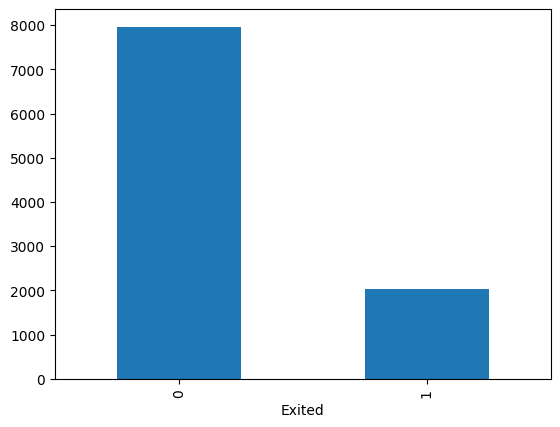

In [9]:
df['Exited'].value_counts().plot(kind='bar')

**Step 4: Model Training & Evaluation**
We train five distinct classification algorithms on the standardized training data and generate predictions on the test set.

In [10]:
# Define dictionary of models
models = {
    "Support Vector Machine (SVM)": SVC(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Neural Network (MLP)": MLPClassifier(max_iter=500, random_state=42)
}

# Dictionary to hold evaluation metrics
results = []

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

print(results)

[{'Model': 'Support Vector Machine (SVM)', 'Accuracy': 0.8615, 'Precision': 0.825, 'Recall': 0.4054, 'F1-Score': 0.5437}, {'Model': 'Decision Tree', 'Accuracy': 0.783, 'Precision': 0.4699, 'Recall': 0.5184, 'F1-Score': 0.493}, {'Model': 'Random Forest', 'Accuracy': 0.856, 'Precision': 0.7148, 'Recall': 0.4865, 'F1-Score': 0.5789}, {'Model': 'Naive Bayes', 'Accuracy': 0.8205, 'Precision': 0.6026, 'Recall': 0.3464, 'F1-Score': 0.4399}, {'Model': 'Neural Network (MLP)', 'Accuracy': 0.863, 'Precision': 0.7333, 'Recall': 0.5135, 'F1-Score': 0.604}]


**Final**
Print the results of the five models

In [11]:
from tabulate import tabulate

# Print formatted grid table
print(tabulate(results, headers="keys", tablefmt="grid"))

+------------------------------+------------+-------------+----------+------------+
| Model                        |   Accuracy |   Precision |   Recall |   F1-Score |
+==============================+============+=============+==========+============+
| Support Vector Machine (SVM) |     0.8615 |      0.825  |   0.4054 |     0.5437 |
+------------------------------+------------+-------------+----------+------------+
| Decision Tree                |     0.783  |      0.4699 |   0.5184 |     0.493  |
+------------------------------+------------+-------------+----------+------------+
| Random Forest                |     0.856  |      0.7148 |   0.4865 |     0.5789 |
+------------------------------+------------+-------------+----------+------------+
| Naive Bayes                  |     0.8205 |      0.6026 |   0.3464 |     0.4399 |
+------------------------------+------------+-------------+----------+------------+
| Neural Network (MLP)         |     0.863  |      0.7333 |   0.5135 |     0

In [14]:
# Define dictionary of models with custom hyperparameters
# ADDED: class_weight='balanced' to SVM, Decision Tree, and Random Forest
models = {
    "Support Vector Machine (SVM)": SVC(C=1, kernel='rbf', class_weight='balanced', random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_split=10, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=10, class_weight='balanced', random_state=42),
    "Naive Bayes": GaussianNB(var_smoothing=1e-9),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, alpha=0.001, random_state=42)
}

# Dictionary to hold evaluation metrics
results = []

# Your loop remains exactly the same, but will now generate meaningful metrics for churn
for name, model in models.items():
    # Train
    model.fit(X_train_selected, y_train)

    # Predict
    y_pred = model.predict(X_test_selected)

    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

# Print results as a nice table using pandas
results_df = pd.DataFrame(results)
print(tabulate(results_df, headers="keys", tablefmt="grid"))


+----+------------------------------+------------+-------------+----------+------------+
|    | Model                        |   Accuracy |   Precision |   Recall |   F1-Score |
+====+==============================+============+=============+==========+============+
|  0 | Support Vector Machine (SVM) |     0.4595 |      0.2355 |   0.7371 |     0.3569 |
+----+------------------------------+------------+-------------+----------+------------+
|  1 | Decision Tree                |     0.7615 |      0.4504 |   0.7813 |     0.5714 |
+----+------------------------------+------------+-------------+----------+------------+
|  2 | Random Forest                |     0.8415 |      0.6004 |   0.6609 |     0.6292 |
+----+------------------------------+------------+-------------+----------+------------+
|  3 | Naive Bayes                  |     0.7855 |      0.3514 |   0.0639 |     0.1081 |
+----+------------------------------+------------+-------------+----------+------------+
|  4 | Neural Network

### **Self-Study Exercise**

Build a clustering model using Agglomerative clustering, K-means and DB-SCAN algorithms for the given real-estate and Credit card datasets.